# K vecinos más cercanos (KNN)

Misma partición 70/15/15 (`random_state=42`). Hiperparámetros por F1 macro en validación.
Prueba una sola vez: recall por clase, F1 macro y matriz de confusión.


## 1. Librerías y datos


In [1]:
import pandas as pd
import numpy as np

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 250)

In [2]:
data = pd.read_csv("RT_IOT2022_preparado.csv")
data.shape

(117922, 49)

In [3]:
data["tipo_ataque"].value_counts()

tipo_ataque
DOS_SYN_Hping                 90089
Thing_Speak                    7654
ARP_poisioning                 7625
MQTT_Publish                   4142
NMAP_UDP_SCAN                  2584
NMAP_XMAS_TREE_SCAN            2010
NMAP_OS_DETECTION              2000
NMAP_TCP_scan                  1002
DDOS_Slowloris                  533
Wipro_bulb                      219
Metasploit_Brute_Force_SSH       36
NMAP_FIN_SCAN                    28
Name: count, dtype: int64

## 2. Preprocesamiento

One-hot de protocolo/servicio, reglas y atípicos, split 70/15/15, códigos del target,
`log1p` (asimetría > 0.85) y StandardScaler / MinMaxScaler (fit solo en train).


### One-hot
`protocolo` y `servicio` van a dummies para que KNN no trate las categorías como números ordenados.


In [4]:
data = pd.get_dummies(data, columns=["protocolo"], prefix="protocolo", dtype=int)
data = pd.get_dummies(data, columns=["servicio"], prefix="servicio", dtype=int)
data.shape

(117922, 60)

In [5]:
col_target = "tipo_ataque"

cols_binarias = [
    "protocolo_icmp", "protocolo_tcp", "protocolo_udp",
    "servicio_-", "servicio_dhcp", "servicio_dns", "servicio_http", "servicio_irc",
    "servicio_mqtt", "servicio_ntp", "servicio_radius", "servicio_ssh", "servicio_ssl",
    "ida_bandera_URG",
]

cols_numericas = [
    # int
    "puerto_destino", "ida_cabecera_min", "ida_cabecera_max", "vuelta_cabecera_min", "vuelta_cabecera_max",
    "bandera_FIN", "bandera_SYN", "bandera_RST", "ida_bandera_PSH", "vuelta_bandera_PSH", "bandera_ACK",
    "ida_ventana_inicial", "vuelta_ventana_inicial",
    # float
    "ida_paquetes_por_seg", "razon_vuelta_ida",
    "ida_carga_min", "ida_carga_max", "ida_carga_prom", "ida_carga_desv",
    "vuelta_carga_min", "vuelta_carga_max", "vuelta_carga_prom", "vuelta_carga_desv",
    "flujo_carga_min", "flujo_carga_prom", "flujo_carga_desv",
    "ida_intervalo_min", "ida_intervalo_max", "ida_intervalo_prom", "ida_intervalo_desv",
    "vuelta_intervalo_min", "vuelta_intervalo_max", "vuelta_intervalo_prom", "vuelta_intervalo_desv",
    "flujo_intervalo_min", "flujo_intervalo_max", "flujo_intervalo_prom", "flujo_intervalo_desv",
    "flujo_bytes_por_seg",
    "activo_min", "activo_max", "activo_prom", "activo_desv",
    "inactivo_prom", "inactivo_desv",
]

print(f"Target: {col_target}")
print(f"Binarias: {len(cols_binarias)}")
print(f"Numéricas: {len(cols_numericas)}")
print(f"Total: {1 + len(cols_binarias) + len(cols_numericas)} de {data.shape[1]} columnas")

Target: tipo_ataque
Binarias: 14
Numéricas: 45
Total: 60 de 60 columnas


### Reglas


In [6]:
num = data[cols_numericas]

r1 = num.isna().any(axis=1)
r2 = np.isinf(num).any(axis=1)
r3 = (num < 0).any(axis=1)
r4 = data["puerto_destino"] > 65535
r5 = data["ida_carga_min"] > data["ida_carga_max"]
r6 = data["vuelta_carga_min"] > data["vuelta_carga_max"]
r7 = data["flujo_intervalo_min"] > data["flujo_intervalo_max"]

print("Nulos:", r1.sum())
print("Infinitos:", r2.sum())
print("Negativos:", r3.sum())
print("Puerto inválido:", r4.sum())
print("Carga ida min > max:", r5.sum())
print("Carga vuelta min > max:", r6.sum())
print("Intervalo min > max:", r7.sum())


Nulos: 0
Infinitos: 0
Negativos: 0
Puerto inválido: 0
Carga ida min > max: 0
Carga vuelta min > max: 0
Intervalo min > max: 0


### Atípicos
|z| > 3 si es simétrica, IQR si no.


In [7]:
filas = []
atipicos = pd.DataFrame(index=data.index)

for col in cols_numericas:
    x = data[col]
    asim = x.skew()

    if abs(asim) <= 0.5:
        metodo = "Z (simétrica)"
        z = (x - x.mean()) / x.std() if x.std() != 0 else 0
        atipico = abs(z) > 3
    else:
        metodo = "IQR (asimétrica)"
        q1, q3 = x.quantile([0.25, 0.75])
        iqr = q3 - q1
        atipico = (x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)

    atipicos[col] = atipico
    filas.append({
        "variable": col,
        "asimetría": round(asim, 2),
        "método": metodo,
        "mediana": x.median(),
        "max": x.max(),
        "% atípicos": round(atipico.mean() * 100, 1),
    })

tabla_atipicos = pd.DataFrame(filas).sort_values("% atípicos", ascending=False)
print(tabla_atipicos["método"].value_counts())
tabla_atipicos.head(15)

método
IQR (asimétrica)    42
Z (simétrica)        3
Name: count, dtype: int64


,variable,asimetría,método,mediana,max,% atípicos
24,flujo_carga_prom,6.40,IQR (asimétrica),60.000000,1.156085e+03,31.3
10,bandera_ACK,210.42,IQR (asimétrica),1.000000,1.177200e+04,27.1
3,vuelta_cabecera_min,-0.98,IQR (asimétrica),20.000000,4.000000e+01,26.2
11,ida_ventana_inicial,2.75,IQR (asimétrica),64.000000,6.553500e+04,23.6
0,puerto_destino,7.82,IQR (asimétrica),21.000000,6.538900e+04,23.6
15,ida_carga_min,-1.09,IQR (asimétrica),120.000000,1.097000e+03,23.6
17,ida_carga_prom,1.61,IQR (asimétrica),120.000000,1.319365e+03,23.6
16,ida_carga_max,7.24,IQR (asimétrica),120.000000,1.420000e+03,23.6
7,bandera_RST,-0.57,IQR (asimétrica),1.000000,1.000000e+01,22.7
14,razon_vuelta_ida,-1.81,IQR (asimétrica),1.000000,6.087899e+00,21.1


In [8]:
fila_atipica = atipicos.any(axis=1)

resumen = pd.DataFrame({
    "registros": data[col_target].value_counts(),
    "con algún atípico": data.loc[fila_atipica, col_target].value_counts(),
}).fillna(0).astype(int)
resumen["% atípicos"] = (resumen["con algún atípico"] / resumen["registros"] * 100).round(1)

print(f"Filas con al menos un atípico: {fila_atipica.mean() * 100:.1f}%")
resumen.sort_values("% atípicos")

Filas con al menos un atípico: 31.5%


,registros,con algún atípico,% atípicos
tipo_ataque,,,
DOS_SYN_Hping,90089,9306,10.3
Thing_Speak,7654,7654,100.0
ARP_poisioning,7625,7625,100.0
MQTT_Publish,4142,4142,100.0
NMAP_UDP_SCAN,2584,2584,100.0
NMAP_XMAS_TREE_SCAN,2010,2010,100.0
NMAP_OS_DETECTION,2000,2000,100.0
NMAP_TCP_scan,1002,1002,100.0
DDOS_Slowloris,533,533,100.0


Los atípicos **no se borran**: casi todas las clases chicas tienen. Se dejan y después el log los comprime.


### Partición
70% train, 15% val, 15% test, estratificado. También se guarda una copia sin transformar para la sección 3.


In [9]:
from sklearn.model_selection import train_test_split

X = data.drop(columns=col_target)
y = data[col_target]

X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.15, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.15 / 0.85, stratify=y_temp, random_state=42)

X_train = X_train.copy()
X_val = X_val.copy()
X_test = X_test.copy()

X_train_sin = X_train.copy()
X_val_sin = X_val.copy()

print(f"Entrenamiento: {X_train.shape[0]:,} | Validación: {X_val.shape[0]:,} | Prueba: {X_test.shape[0]:,}")

Entrenamiento: 82,544 | Validación: 17,689 | Prueba: 17,689


### Target
Códigos 0–11, igual que en la red.


In [10]:
codigos = {
    "ARP_poisioning": 0,
    "DDOS_Slowloris": 1,
    "DOS_SYN_Hping": 2,
    "MQTT_Publish": 3,
    "Metasploit_Brute_Force_SSH": 4,
    "NMAP_FIN_SCAN": 5,
    "NMAP_OS_DETECTION": 6,
    "NMAP_TCP_scan": 7,
    "NMAP_UDP_SCAN": 8,
    "NMAP_XMAS_TREE_SCAN": 9,
    "Thing_Speak": 10,
    "Wipro_bulb": 11,
}
clases = list(codigos)

y_train = y_train.map(codigos)
y_val = y_val.map(codigos)
y_test = y_test.map(codigos)

ssh = codigos["Metasploit_Brute_Force_SSH"]
fin = codigos["NMAP_FIN_SCAN"]

pd.DataFrame({
    "entrenamiento": y_train.value_counts(),
    "validación": y_val.value_counts(),
    "prueba": y_test.value_counts(),
}).sort_index().set_index(pd.Index(clases, name="clase"))

,entrenamiento,validación,prueba
clase,,,
ARP_poisioning,5337,1144,1144
DDOS_Slowloris,373,80,80
DOS_SYN_Hping,63061,13514,13514
MQTT_Publish,2900,621,621
Metasploit_Brute_Force_SSH,25,6,5
NMAP_FIN_SCAN,20,4,4
NMAP_OS_DETECTION,1400,300,300
NMAP_TCP_scan,702,150,150
NMAP_UDP_SCAN,1808,388,388


### Log
`log1p` a columnas con asimetría > 0.85 en train.


In [11]:
umbral = 0.85

asimetria = X_train[cols_numericas].skew()
cols_log = asimetria[asimetria > umbral].index.tolist()

X_train[cols_log] = np.log1p(X_train[cols_log])
X_val[cols_log] = np.log1p(X_val[cols_log])
X_test[cols_log] = np.log1p(X_test[cols_log])

print(f"Con log ({len(cols_log)}):", cols_log)

Con log (38): ['puerto_destino', 'ida_cabecera_max', 'bandera_FIN', 'ida_bandera_PSH', 'vuelta_bandera_PSH', 'bandera_ACK', 'ida_ventana_inicial', 'vuelta_ventana_inicial', 'ida_paquetes_por_seg', 'ida_carga_max', 'ida_carga_prom', 'ida_carga_desv', 'vuelta_carga_min', 'vuelta_carga_max', 'vuelta_carga_prom', 'vuelta_carga_desv', 'flujo_carga_min', 'flujo_carga_prom', 'flujo_carga_desv', 'ida_intervalo_min', 'ida_intervalo_max', 'ida_intervalo_prom', 'ida_intervalo_desv', 'vuelta_intervalo_min', 'vuelta_intervalo_max', 'vuelta_intervalo_prom', 'vuelta_intervalo_desv', 'flujo_intervalo_min', 'flujo_intervalo_max', 'flujo_intervalo_prom', 'flujo_intervalo_desv', 'flujo_bytes_por_seg', 'activo_min', 'activo_max', 'activo_prom', 'activo_desv', 'inactivo_prom', 'inactivo_desv']


In [12]:
asimetria_log = X_train[cols_numericas].skew()

cols_simetricas = asimetria_log[asimetria_log.abs() <= umbral].index.tolist()
cols_asimetricas = asimetria_log[asimetria_log.abs() > umbral].index.tolist()

print(f"Simétricas -> StandardScaler ({len(cols_simetricas)}):", cols_simetricas)
print(f"Asimétricas -> MinMaxScaler ({len(cols_asimetricas)}):", cols_asimetricas)

Simétricas -> StandardScaler (5): ['ida_cabecera_min', 'ida_cabecera_max', 'vuelta_cabecera_max', 'bandera_SYN', 'bandera_RST']
Asimétricas -> MinMaxScaler (40): ['puerto_destino', 'vuelta_cabecera_min', 'bandera_FIN', 'ida_bandera_PSH', 'vuelta_bandera_PSH', 'bandera_ACK', 'ida_ventana_inicial', 'vuelta_ventana_inicial', 'ida_paquetes_por_seg', 'razon_vuelta_ida', 'ida_carga_min', 'ida_carga_max', 'ida_carga_prom', 'ida_carga_desv', 'vuelta_carga_min', 'vuelta_carga_max', 'vuelta_carga_prom', 'vuelta_carga_desv', 'flujo_carga_min', 'flujo_carga_prom', 'flujo_carga_desv', 'ida_intervalo_min', 'ida_intervalo_max', 'ida_intervalo_prom', 'ida_intervalo_desv', 'vuelta_intervalo_min', 'vuelta_intervalo_max', 'vuelta_intervalo_prom', 'vuelta_intervalo_desv', 'flujo_intervalo_min', 'flujo_intervalo_max', 'flujo_intervalo_prom', 'flujo_intervalo_desv', 'flujo_bytes_por_seg', 'activo_min', 'activo_max', 'activo_prom', 'activo_desv', 'inactivo_prom', 'inactivo_desv']


In [13]:
comparacion_log = pd.DataFrame({
    "antes": asimetria[cols_log],
    "después": asimetria_log[cols_log],
}).sort_values("antes", ascending=False)

print(f"Mediana |asimetría| antes: {comparacion_log['antes'].abs().median():.2f} | después: {comparacion_log['después'].abs().median():.2f}")
print(f"Columnas con |asimetría| > 10 antes: {(comparacion_log['antes'].abs() > 10).sum()} | después: {(comparacion_log['después'].abs() > 10).sum()}")
comparacion_log.head(10)

Mediana |asimetría| antes: 9.98 | después: 2.61
Columnas con |asimetría| > 10 antes: 19 | después: 1


,antes,después
activo_desv,241.823439,8.550034
activo_min,203.312442,2.111660
activo_max,199.553253,2.083411
ida_intervalo_min,196.253269,3.004943
bandera_ACK,193.695246,2.448673
activo_prom,185.261575,2.079078
ida_bandera_PSH,164.055421,3.360593
vuelta_bandera_PSH,155.953505,3.988667
vuelta_intervalo_min,152.359340,2.893312
flujo_intervalo_min,129.546609,2.801460


### Escalado
Sin escalar las distancias las mandan las variables grandes. StandardScaler en simétricas, MinMax en el resto.


In [14]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

standard = StandardScaler()
X_train[cols_simetricas] = standard.fit_transform(X_train[cols_simetricas])
X_val[cols_simetricas] = standard.transform(X_val[cols_simetricas])
X_test[cols_simetricas] = standard.transform(X_test[cols_simetricas])

minmax = MinMaxScaler()
X_train[cols_asimetricas] = minmax.fit_transform(X_train[cols_asimetricas])
X_val[cols_asimetricas] = minmax.transform(X_val[cols_asimetricas])
X_test[cols_asimetricas] = minmax.transform(X_test[cols_asimetricas])

In [15]:
pd.set_option("display.float_format", "{:,.2f}".format)
X_train[cols_numericas].describe().T[["mean", "std", "min", "max"]].head(15)

,mean,std,min,max
puerto_destino,0.35,0.16,0.00,1.00
ida_cabecera_min,-0.00,1.00,-3.68,4.51
ida_cabecera_max,-0.00,1.00,-8.75,2.75
vuelta_cabecera_min,0.44,0.20,0.00,1.00
vuelta_cabecera_max,0.00,1.00,-1.96,2.70
bandera_FIN,0.03,0.11,0.00,1.00
bandera_SYN,-0.00,1.00,-1.98,10.54
bandera_RST,-0.00,1.00,-1.82,21.03
ida_bandera_PSH,0.02,0.06,0.00,1.00
vuelta_bandera_PSH,0.02,0.06,0.00,1.00


## 3. Preprocesamiento y KNN

Mismo KNN base (k=5) con distintas versiones de los datos, medido en validación.


In [16]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score, recall_score


def evaluar(modelo, X, y):
    pred = modelo.predict(X)
    recall = recall_score(y, pred, labels=range(12), average=None, zero_division=0)
    return {
        "exactitud": accuracy_score(y, pred),
        "f1_macro": f1_score(y, pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y, pred, average="macro", zero_division=0),
        "recall_SSH": recall[ssh],
        "recall_FIN": recall[fin],
    }

In [17]:
from sklearn.preprocessing import RobustScaler

versiones = {"Sin escalar": (X_train_sin, X_val_sin)}

for nombre, escalador in [("Solo StandardScaler", StandardScaler()),
                          ("Solo MinMaxScaler", MinMaxScaler()),
                          ("Solo RobustScaler", RobustScaler())]:
    Xa, Xb = X_train_sin.copy(), X_val_sin.copy()
    Xa[cols_numericas] = escalador.fit_transform(Xa[cols_numericas])
    Xb[cols_numericas] = escalador.transform(Xb[cols_numericas])
    versiones[nombre] = (Xa, Xb)

versiones["log1p + Standard/MinMax (pipeline)"] = (X_train, X_val)

p1 = X_train[cols_numericas].quantile(0.01)
p99 = X_train[cols_numericas].quantile(0.99)
Xa, Xb = X_train.copy(), X_val.copy()
Xa[cols_numericas] = Xa[cols_numericas].clip(p1, p99, axis=1)
Xb[cols_numericas] = Xb[cols_numericas].clip(p1, p99, axis=1)
versiones["Pipeline + recorte de atípicos p1-p99"] = (Xa, Xb)

filas = []
for nombre, (Xa, Xb) in versiones.items():
    modelo = KNeighborsClassifier(n_neighbors=5, n_jobs=-1).fit(Xa, y_train)
    filas.append({"preprocesamiento": nombre, **evaluar(modelo, Xb, y_val)})

pd.set_option("display.float_format", "{:.4f}".format)
tabla_prep = pd.DataFrame(filas).set_index("preprocesamiento")
tabla_prep

,exactitud,f1_macro,recall_macro,recall_SSH,recall_FIN
preprocesamiento,,,,,
Sin escalar,0.9753,0.8422,0.8407,0.8333,1.0000
Solo StandardScaler,0.9947,0.9425,0.9480,0.8333,1.0000
Solo MinMaxScaler,0.9957,0.9415,0.9517,0.8333,1.0000
Solo RobustScaler,0.9751,0.8377,0.8451,0.8333,1.0000
log1p + Standard/MinMax (pipeline),0.9950,0.9450,0.9505,0.8333,1.0000
Pipeline + recorte de atípicos p1-p99,0.9951,0.9473,0.9531,0.8333,1.0000


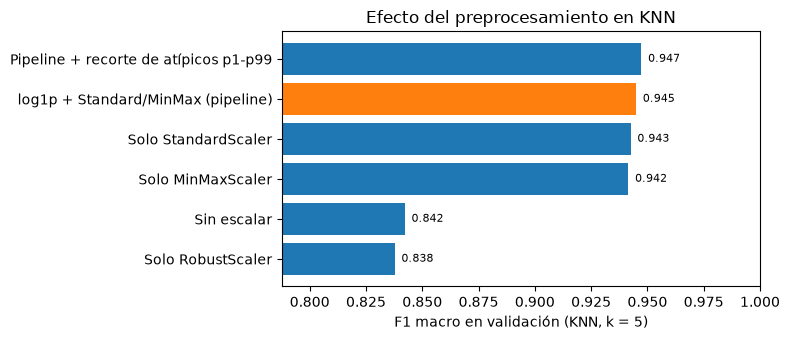

In [18]:
import matplotlib.pyplot as plt
from pathlib import Path

Path("resultados/knn").mkdir(parents=True, exist_ok=True)

orden = tabla_prep["f1_macro"].sort_values().index
colores = ["tab:orange" if "pipeline" in n else "tab:blue" for n in orden]

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(orden, tabla_prep.loc[orden, "f1_macro"], color=colores)
for i, n in enumerate(orden):
    ax.text(tabla_prep.loc[n, "f1_macro"] + 0.003, i, f"{tabla_prep.loc[n, 'f1_macro']:.3f}", va="center", fontsize=8)
ax.set_xlim(tabla_prep["f1_macro"].min() - 0.05, 1)
ax.set_xlabel("F1 macro en validación (KNN, k = 5)")
ax.set_title("Efecto del preprocesamiento en KNN")
plt.tight_layout()
plt.savefig("resultados/knn/knn_preprocesamiento.png", dpi=200)
plt.show()

In [19]:
# misma idea pero ajustando k / pesos / distancia
filas = []
for nombre in ["Solo StandardScaler", "Solo MinMaxScaler", "log1p + Standard/MinMax (pipeline)", "Pipeline + recorte de atípicos p1-p99"]:
    Xa, Xb = versiones[nombre]
    mejor_f1 = 0
    for k in [1, 3, 5, 7, 9, 11]:
        for pesos in ["uniform", "distance"]:
            for p in [1, 2]:
                modelo = KNeighborsClassifier(n_neighbors=k, weights=pesos, p=p, n_jobs=-1).fit(Xa, y_train)
                f1 = f1_score(y_val, modelo.predict(Xb), average="macro", zero_division=0)
                if f1 > mejor_f1:
                    mejor_f1, mejor_config = f1, f"k = {k}, {pesos}, p = {p}"
    filas.append({
        "preprocesamiento": nombre,
        "f1_macro_val (k = 5)": tabla_prep.loc[nombre, "f1_macro"],
        "f1_macro_val ajustado": mejor_f1,
        "mejor configuración": mejor_config,
    })



Sin escalar el F1 macro en val baja (0.842; con RobustScaler 0.838). Al escalar sube a ~0.94–0.95.

Se deja el pipeline del grupo (log + Standard/MinMax) para que los 4 modelos usen lo mismo; además ahora es el mejor
de las versiones sin recorte (F1 macro val 0.945 vs 0.943 Standard y 0.942 MinMax).
Recortar p1–p99 apenas mejora a KNN (0.947), pero eso sería otro preprocesamiento.

## 4. Hiperparámetros

Se prueban k, `uniform`/`distance` y Manhattan/euclidiana.
Gana el mayor F1 macro en validación (si empatan, el de menor k).


In [20]:
ks = [1, 3, 5, 7, 9, 11, 15, 21, 31, 51]

filas = []
for p, distancia in [(1, "manhattan"), (2, "euclidiana")]:
    for pesos in ["uniform", "distance"]:
        for k in ks:
            modelo = KNeighborsClassifier(n_neighbors=k, weights=pesos, p=p, n_jobs=-1).fit(X_train, y_train)
            f1_train = f1_score(y_train, modelo.predict(X_train), average="macro", zero_division=0)
            val = evaluar(modelo, X_val, y_val)
            filas.append({"k": k, "pesos": pesos, "distancia": distancia, "p": p, "f1_train": f1_train,
                          **{f"{m}_val": v for m, v in val.items()}})

busqueda = pd.DataFrame(filas)
mejor = busqueda.sort_values(["f1_macro_val", "k"], ascending=[False, True]).iloc[0]
mejor_k, mejor_pesos, mejor_p = int(mejor["k"]), mejor["pesos"], int(mejor["p"])

print(f"Mejor: k = {mejor_k}, pesos = {mejor_pesos}, distancia = {mejor['distancia']} -> F1 macro validación = {mejor['f1_macro_val']:.4f}")
busqueda.sort_values("f1_macro_val", ascending=False).head(10)

Mejor: k = 3, pesos = distance, distancia = euclidiana -> F1 macro validación = 0.9582


,k,pesos,distancia,p,f1_train,exactitud_val,f1_macro_val,recall_macro_val,recall_SSH_val,recall_FIN_val
31,3,distance,euclidiana,2,0.9981,0.9963,0.9582,0.9664,0.8333,1.0000
39,51,distance,euclidiana,2,0.9981,0.9945,0.9561,0.9369,0.8333,1.0000
32,5,distance,euclidiana,2,0.9981,0.9960,0.9558,0.9649,0.8333,1.0000
19,51,distance,manhattan,1,0.9981,0.9949,0.9554,0.9489,0.8333,1.0000
11,3,distance,manhattan,1,0.9981,0.9968,0.9529,0.9636,0.8333,1.0000
12,5,distance,manhattan,1,0.9981,0.9966,0.9511,0.9632,0.8333,1.0000
21,3,uniform,euclidiana,2,0.9687,0.9954,0.9508,0.9572,0.8333,1.0000
20,1,uniform,euclidiana,2,0.9981,0.9960,0.9484,0.9616,0.8333,1.0000
30,1,distance,euclidiana,2,0.9981,0.9960,0.9484,0.9616,0.8333,1.0000
1,3,uniform,manhattan,1,0.9677,0.9962,0.9458,0.9565,0.8333,1.0000


In [21]:
busqueda.pivot_table(index=["distancia", "pesos"], columns="k", values="f1_macro_val")

k                       1      3      5      7      9      11     15     21     31     51
distancia  pesos                                                                         
euclidiana distance 0.9484 0.9582 0.9558 0.9448 0.9420 0.9414 0.9429 0.9387 0.9378 0.9561
           uniform  0.9484 0.9508 0.9450 0.9398 0.9404 0.9364 0.9297 0.9238 0.9218 0.7738
manhattan  distance 0.9431 0.9529 0.9511 0.9429 0.9416 0.9401 0.9392 0.9381 0.9373 0.9554
           uniform  0.9431 0.9458 0.9427 0.9384 0.9331 0.9313 0.9288 0.9248 0.9283 0.7895

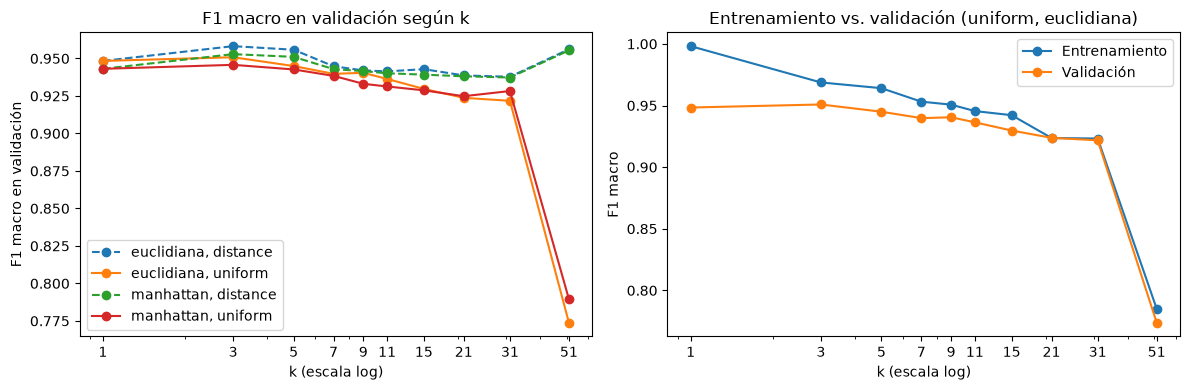

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for (distancia, pesos), g in busqueda.groupby(["distancia", "pesos"]):
    axes[0].plot(g["k"], g["f1_macro_val"], marker="o", ls="-" if pesos == "uniform" else "--", label=f"{distancia}, {pesos}")
axes[0].set_xscale("log")
axes[0].set_xticks(ks)
axes[0].set_xticklabels(ks)
axes[0].set_xlabel("k (escala log)")
axes[0].set_ylabel("F1 macro en validación")
axes[0].set_title("F1 macro en validación según k")
axes[0].legend()

g = busqueda[(busqueda["pesos"] == "uniform") & (busqueda["p"] == mejor_p)]
axes[1].plot(g["k"], g["f1_train"], marker="o", label="Entrenamiento")
axes[1].plot(g["k"], g["f1_macro_val"], marker="o", label="Validación")
axes[1].set_xscale("log")
axes[1].set_xticks(ks)
axes[1].set_xticklabels(ks)
axes[1].set_xlabel("k (escala log)")
axes[1].set_ylabel("F1 macro")
axes[1].set_title(f"Entrenamiento vs. validación (uniform, {g['distancia'].iloc[0]})")
axes[1].legend()

plt.tight_layout()
plt.savefig("resultados/knn/knn_ajuste_k.png", dpi=200)
plt.show()

In [23]:
# recall SSH/FIN en val según k
g = busqueda[(busqueda["pesos"] == mejor_pesos) & (busqueda["p"] == mejor_p)]


Mejor: **k=3, distance, euclidiana** (F1 macro val 0.9582). Antes ganaba Manhattan; ahora queda detrás
(k=3, distance, Manhattan: 0.9529).

Con voto uniforme, al subir k cae el F1 (con k=51 baja a 0.774 euclidiana / 0.790 Manhattan: las clases chicas pierden).
Con `distance` se mantiene mejor (≥ 0.937 en todos los k).
SSH en val: recall 0.83 (5 de 6); FIN: 1.00.

## 5. Modelo final (prueba)
Con la config elegida en validación, se reentrena con train + val (igual que la red). Test una sola vez.


In [24]:
import time

X_train_val = pd.concat([X_train, X_val])
y_train_val = pd.concat([y_train, y_val])

t0 = time.perf_counter()
modelo_final = KNeighborsClassifier(n_neighbors=mejor_k, weights=mejor_pesos, p=mejor_p, n_jobs=-1).fit(X_train_val, y_train_val)
t_entrenamiento = time.perf_counter() - t0

t0 = time.perf_counter()
pred_test = modelo_final.predict(X_test)
t_prediccion = time.perf_counter() - t0

# la validación ya está dentro del modelo: su F1 macro (elección de k) queda en `busqueda`
metricas = pd.DataFrame({
    "entrenamiento + validación": evaluar(modelo_final, X_train_val, y_train_val),
    "prueba": evaluar(modelo_final, X_test, y_test),
}).T
metricas

,exactitud,f1_macro,recall_macro,recall_SSH,recall_FIN
entrenamiento + validación,0.9999,0.9985,0.9996,1.0000,1.0000
prueba,0.9972,0.9752,0.9879,1.0000,1.0000


In [25]:
from sklearn.metrics import classification_report

print(classification_report(y_test, pred_test, labels=range(12), target_names=clases, digits=3, zero_division=0))

                            precision    recall  f1-score   support

            ARP_poisioning      0.983     0.992     0.987      1144
            DDOS_Slowloris      0.918     0.975     0.945        80
             DOS_SYN_Hping      1.000     1.000     1.000     13514
              MQTT_Publish      1.000     0.998     0.999       621
Metasploit_Brute_Force_SSH      0.833     1.000     0.909         5
             NMAP_FIN_SCAN      1.000     1.000     1.000         4
         NMAP_OS_DETECTION      1.000     1.000     1.000       300
             NMAP_TCP_scan      1.000     1.000     1.000       150
             NMAP_UDP_SCAN      0.987     0.972     0.979       388
       NMAP_XMAS_TREE_SCAN      1.000     1.000     1.000       302
               Thing_Speak      0.989     0.978     0.984      1148
                Wipro_bulb      0.861     0.939     0.899        33

                  accuracy                          0.997     17689
                 macro avg      0.964     0.98

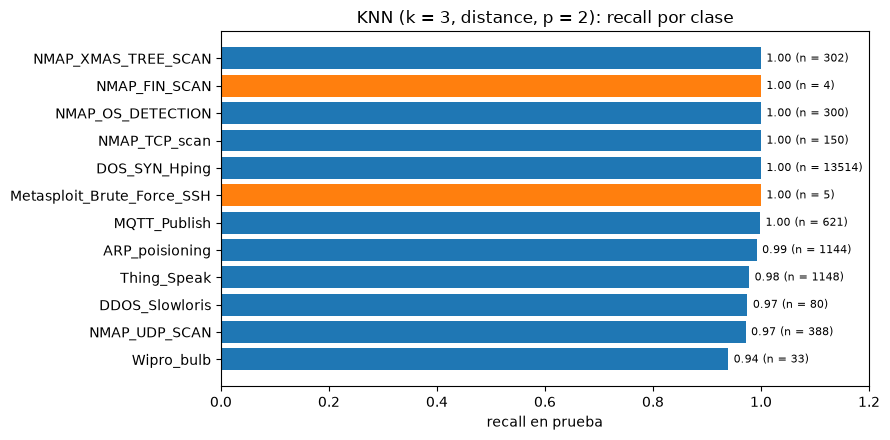

In [26]:
reporte = pd.DataFrame(classification_report(y_test, pred_test, labels=range(12), target_names=clases,
                                             output_dict=True, zero_division=0)).T.loc[clases]
reporte["support"] = reporte["support"].astype(int)

orden = reporte.sort_values("recall").index
colores = ["tab:orange" if c in ["Metasploit_Brute_Force_SSH", "NMAP_FIN_SCAN"] else "tab:blue" for c in orden]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(orden, reporte.loc[orden, "recall"], color=colores)
for i, c in enumerate(orden):
    ax.text(reporte.loc[c, "recall"] + 0.01, i, f"{reporte.loc[c, 'recall']:.2f} (n = {reporte.loc[c, 'support']})", va="center", fontsize=8)
ax.set_xlim(0, 1.2)
ax.set_xlabel("recall en prueba")
ax.set_title(f"KNN (k = {mejor_k}, {mejor_pesos}, p = {mejor_p}): recall por clase")
plt.tight_layout()
plt.savefig("resultados/knn/knn_recall_por_clase.png", dpi=200)
plt.show()

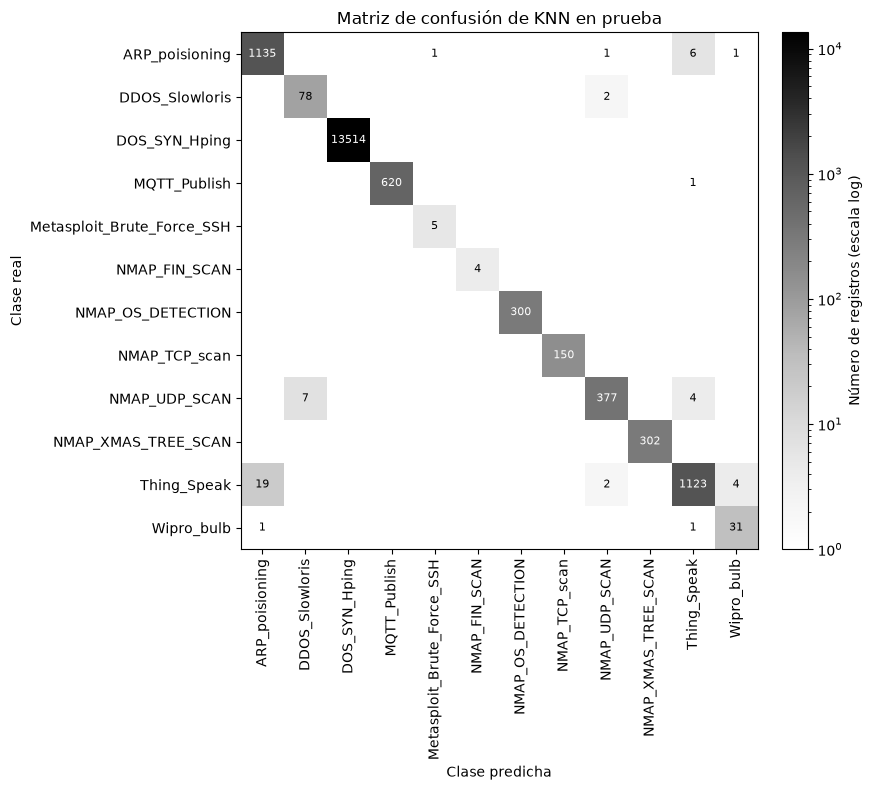

In [27]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from matplotlib.colors import LogNorm

cm = confusion_matrix(y_test, pred_test, labels=range(12))

### Escala logarítmica para que DOS_SYN_Hping no tape los errores (las celdas en 0 quedan en blanco)

cm_log = np.ma.masked_equal(cm, 0)
cmap = plt.get_cmap("Greys").copy()
cmap.set_bad("white")

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(cm_log, cmap=cmap, norm=LogNorm(vmin=1, vmax=cm.max()))
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        if cm[i, j] > 0:
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                    color="white" if im.norm(cm[i, j]) > 0.5 else "black")
ax.set_xticks(range(len(clases)), clases, rotation=90)
ax.set_yticks(range(len(clases)), clases)
ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase real")
ax.set_title("Matriz de confusión de KNN en prueba")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Número de registros (escala log)")
plt.tight_layout()
plt.savefig("resultados/knn/knn_matriz_confusion.png", dpi=300)
plt.show()

In [28]:
# errores en prueba
errores = pd.DataFrame(cm, index=clases, columns=clases).stack()
errores = errores[(errores.index.get_level_values(0) != errores.index.get_level_values(1)) & (errores > 0)]


Prueba: exactitud 0.997, F1 macro 0.975, recall macro 0.988.

SSH 5/5 (precision 0.83 por un FP de ARP: un flujo UDP/DNS al puerto 53). FIN 4/4 con precision 1.00.
Clases con menor F1: Wipro_bulb (0.899), SSH (0.909), DDOS_Slowloris (0.945) y NMAP_UDP_SCAN (0.979).
Errores típicos: ThingSpeak ↔ ARP (19 + 6), UDP ↔ Slowloris (7 + 2), ThingSpeak → Wipro (4) y UDP → ThingSpeak (4).


## 6. Exactitud vs F1

Se compara el KNN final con uno que "se olvida" de SSH/FIN y con un dummy de clase mayoritaria.


In [29]:
from sklearn.dummy import DummyClassifier

pred_sin_raras = pred_test.copy()
pred_sin_raras[np.isin(y_test, [ssh, fin])] = codigos["DOS_SYN_Hping"]
pred_trivial = DummyClassifier(strategy="most_frequent").fit(X_train_val, y_train_val).predict(X_test)

filas = []
for nombre, pred in [("KNN final", pred_test),
                     ("KNN que nunca marca SSH ni FIN", pred_sin_raras),
                     ("Siempre la clase más frecuente", pred_trivial)]:
    recall = recall_score(y_test, pred, labels=range(12), average=None, zero_division=0)
    filas.append({
        "modelo": nombre,
        "exactitud": accuracy_score(y_test, pred),
        "f1_macro": f1_score(y_test, pred, average="macro", zero_division=0),
        "f1_ponderado": f1_score(y_test, pred, average="weighted", zero_division=0),
        "recall_SSH": recall[ssh],
        "recall_FIN": recall[fin],
    })

print(f"SSH + FIN en prueba: {np.isin(y_test, [ssh, fin]).sum()} de {len(y_test):,} registros")
contraste = pd.DataFrame(filas).set_index("modelo")
contraste

SSH + FIN en prueba: 9 de 17,689 registros


,exactitud,f1_macro,f1_ponderado,recall_SSH,recall_FIN
modelo,,,,,
KNN final,0.9972,0.9752,0.9972,1.0000,1.0000
KNN que nunca marca SSH ni FIN,0.9967,0.8161,0.9964,0.0000,0.0000
Siempre la clase más frecuente,0.7640,0.0722,0.6618,0.0000,0.0000


Si no se marcaran SSH ni FIN, la exactitud casi no se mueve (0.9972 → 0.9967), pero el F1 macro cae ~16 puntos
(0.975 → 0.816). Hay que mirar F1 macro y recall por clase.

## 7. SSH y FIN

Se miran predicciones, vecinos y distancia al más cercano (variables originales).


In [30]:
original = pd.read_csv("RT_IOT2022_preparado.csv")
distancias, vecinos = modelo_final.kneighbors(X_test)

cols_ver = ["protocolo", "servicio", "puerto_destino", "ida_paquetes_por_seg", "razon_vuelta_ida",
            "bandera_FIN", "bandera_SYN", "bandera_ACK", "ida_carga_prom"]

filas = []
for clase in [ssh, fin]:
    for i in np.where(y_test == clase)[0]:
        fila = y_test.index[i]
        filas.append({
            "fila": fila,
            "clase real": clases[clase],
            **original.loc[fila, cols_ver].to_dict(),
            "predicción": clases[pred_test[i]],
            "vecinos": ", ".join(clases[c] for c in y_train_val.iloc[vecinos[i]]),
            "distancia al más cercano": round(distancias[i, 0], 4),
        })

pd.set_option("display.max_colwidth", 120)
pd.DataFrame(filas).set_index("fila")

,clase real,protocolo,servicio,puerto_destino,ida_paquetes_por_seg,razon_vuelta_ida,bandera_FIN,bandera_SYN,bandera_ACK,ida_carga_prom,predicción,vecinos,distancia al más cercano
fila,,,,,,,,,,,,,
110291,Metasploit_Brute_Force_SSH,tcp,ssh,22,5.6294,0.8667,2,2,27,83.2667,Metasploit_Brute_Force_SSH,"Metasploit_Brute_Force_SSH, Metasploit_Brute_Force_SSH, Metasploit_Brute_Force_SSH",0.0606
110274,Metasploit_Brute_Force_SSH,tcp,ssh,22,7.2599,0.8667,2,2,27,83.2667,Metasploit_Brute_Force_SSH,"Metasploit_Brute_Force_SSH, Metasploit_Brute_Force_SSH, Metasploit_Brute_Force_SSH",0.0107
110285,Metasploit_Brute_Force_SSH,tcp,ssh,22,7.3766,0.9286,2,2,26,89.2143,Metasploit_Brute_Force_SSH,"Metasploit_Brute_Force_SSH, Metasploit_Brute_Force_SSH, Metasploit_Brute_Force_SSH",0.0431
110284,Metasploit_Brute_Force_SSH,tcp,ssh,22,5.3173,0.8667,2,2,27,83.2667,Metasploit_Brute_Force_SSH,"Metasploit_Brute_Force_SSH, Metasploit_Brute_Force_SSH, Metasploit_Brute_Force_SSH",0.0138
110269,Metasploit_Brute_Force_SSH,tcp,ssh,22,6.7824,0.9286,2,2,26,89.2143,Metasploit_Brute_Force_SSH,"Metasploit_Brute_Force_SSH, Metasploit_Brute_Force_SSH, Metasploit_Brute_Force_SSH",0.0251
110319,NMAP_FIN_SCAN,tcp,-,22,0.0000,0.0000,1,0,0,0.0000,NMAP_FIN_SCAN,"NMAP_FIN_SCAN, NMAP_FIN_SCAN, NMAP_FIN_SCAN",0.0000
110310,NMAP_FIN_SCAN,tcp,-,22,0.0000,0.0000,1,0,0,0.0000,NMAP_FIN_SCAN,"NMAP_FIN_SCAN, NMAP_FIN_SCAN, NMAP_FIN_SCAN",0.0000
110321,NMAP_FIN_SCAN,tcp,-,22,0.0000,0.0000,1,0,0,0.0000,NMAP_FIN_SCAN,"NMAP_FIN_SCAN, NMAP_FIN_SCAN, NMAP_FIN_SCAN",0.0000
110308,NMAP_FIN_SCAN,tcp,-,22,0.0000,0.0000,1,0,0,0.0000,NMAP_FIN_SCAN,"NMAP_FIN_SCAN, NMAP_FIN_SCAN, NMAP_FIN_SCAN",0.0000


In [31]:
# cómo se ven SSH y FIN en el CSV preparado
for nombre in ["Metasploit_Brute_Force_SSH", "NMAP_FIN_SCAN"]:
    print(nombre)
    print(original.loc[original[col_target] == nombre].groupby(["protocolo", "servicio", "puerto_destino"]).size().to_string())


Metasploit_Brute_Force_SSH
protocolo  servicio  puerto_destino
tcp        http      80                 1
           ssh       22                28
udp        dns       53                 4
                     5353               3
NMAP_FIN_SCAN
protocolo  servicio  puerto_destino
tcp        -         22                24
           http      80                 1
udp        dns       53                 3


In [32]:
# copias exactas test vs train + val (por huella de la fila original; distancia == 0 falla por redondeo)
huella = pd.util.hash_pandas_object(original.drop(columns=col_target), index=False)
copia = huella.loc[y_test.index].isin(set(huella.loc[y_train_val.index]))
acierto = pd.Series(pred_test == y_test.values, index=y_test.index)

copias = pd.DataFrame({
    "registros prueba": y_test.value_counts(),
    "con copia exacta en train + val": y_test[copia].value_counts(),
    "recall con copia": acierto[copia].groupby(y_test[copia]).mean(),
    "recall sin copia": acierto[~copia].groupby(y_test[~copia]).mean(),
}).sort_index().set_index(pd.Index(clases, name="clase"))
copias["con copia exacta en train + val"] = copias["con copia exacta en train + val"].fillna(0).astype(int)

print(f"Registros de prueba con copia exacta en train + val: {copia.sum():,} de {len(copia):,} ({copia.mean() * 100:.1f}%)")
print(f"Acierto con copia: {acierto[copia].mean():.4f} | sin copia: {acierto[~copia].mean():.4f} ({(~copia).sum():,} registros)")
copias

Registros de prueba con copia exacta en train + val: 14,218 de 17,689 (80.4%)
Acierto con copia: 0.9997 | sin copia: 0.9867 (3,471 registros)


,registros prueba,con copia exacta en train + val,recall con copia,recall sin copia
clase,,,,
ARP_poisioning,1144,352,0.9943,0.9912
DDOS_Slowloris,80,0,NaN,0.9750
DOS_SYN_Hping,13514,13513,1.0000,1.0000
MQTT_Publish,621,1,1.0000,0.9984
Metasploit_Brute_Force_SSH,5,0,NaN,1.0000
NMAP_FIN_SCAN,4,4,1.0000,NaN
NMAP_OS_DETECTION,300,25,1.0000,1.0000
NMAP_TCP_scan,150,0,NaN,1.0000
NMAP_UDP_SCAN,388,301,0.9934,0.8966


In [33]:
# fallos que tocan SSH o FIN en prueba (val ya está dentro del modelo)
falla = (y_test.values != pred_test) & (np.isin(y_test, [ssh, fin]) | np.isin(pred_test, [ssh, fin]))

filas = []
for i in np.where(falla)[0]:
    fila = y_test.index[i]
    filas.append({
        "fila": fila,
        "clase real": clases[y_test.iloc[i]],
        "predicción": clases[pred_test[i]],
        **original.loc[fila, cols_ver].to_dict(),
    })

pd.DataFrame(filas).set_index("fila")

,clase real,predicción,protocolo,servicio,puerto_destino,ida_paquetes_por_seg,razon_vuelta_ida,bandera_FIN,bandera_SYN,bandera_ACK,ida_carga_prom
fila,,,,,,,,,,,
12875,ARP_poisioning,Metasploit_Brute_Force_SSH,udp,dns,53,40.9484,1.0000,0,0,0,44.0000


SSH en prueba: 5/5, sin copia exacta en train + val (distancia al más cercano 0.011–0.061; sí generaliza un poco).
FP: un registro de ARP (UDP/DNS al 53) marcado como SSH; 7 de los 36 SSH también son UDP/DNS.

FIN en prueba: 4/4, pero con distancia 0 (copia exacta en train + val). Sin FP.

80.4% del test (14 218 de 17 689) tiene copia exacta en train + val; casi todo es DOS (13 513 de 13 514).
Con copia acierta 0.9997; sin copia, 0.987 (3 471 registros). Donde más se nota es UDP: 0.993 con copia vs 0.897 sin copia.
Limitación del dataset.

## 8. Costo
Entrenar es barato; predecir implica recorrer todos los registros guardados (train + val).


In [34]:
costo = pd.Series({
    "tiempo de entrenamiento (s)": round(t_entrenamiento, 3),
    "tiempo de predicción en prueba (s)": round(t_prediccion, 3),
    "ms por registro predicho": round(t_prediccion / len(X_test) * 1000, 4),
    "registros guardados por el modelo": len(X_train_val),
    "memoria de los datos guardados (MB)": round(X_train_val.values.nbytes / 1e6, 1),
}).to_frame("KNN final")
costo

,KNN final
tiempo de entrenamiento (s),0.0330
tiempo de predicción en prueba (s),1.6420
ms por registro predicho,0.0928
registros guardados por el modelo,100233.0000
memoria de los datos guardados (MB),47.3000


## 9. Resultados guardados
Salida en `resultados/knn/` para la tabla de los 4 modelos.


In [35]:
Path("resultados/knn").mkdir(parents=True, exist_ok=True)

metricas.assign(modelo="KNN", k=mejor_k, pesos=mejor_pesos, p=mejor_p).rename_axis("conjunto").to_csv("resultados/knn/metricas_knn.csv")
reporte.to_csv("resultados/knn/reporte_por_clase_prueba.csv")
pd.DataFrame(cm, index=clases, columns=clases).to_csv("resultados/knn/matriz_confusion_prueba.csv")
busqueda.to_csv("resultados/knn/busqueda_hiperparametros.csv", index=False)
tabla_prep.to_csv("resultados/knn/comparacion_preprocesamiento.csv")
contraste.to_csv("resultados/knn/contraste_exactitud_f1.csv")

sorted(p.name for p in Path("resultados/knn").iterdir())

['busqueda_hiperparametros.csv',
 'comparacion_preprocesamiento.csv',
 'contraste_exactitud_f1.csv',
 'fig1_metricas_globales.png',
 'fig2_matriz_y_metricas_ssh_fin.png',
 'knn_ajuste_k.png',
 'knn_matriz_confusion.png',
 'knn_preprocesamiento.png',
 'knn_recall_por_clase.png',
 'matriz_confusion_prueba.csv',
 'metricas_knn.csv',
 'reporte_por_clase_prueba.csv']

## 10. Conclusiones

- Escala sí o sí: sin escalar F1 macro val ~0.84; con el pipeline ~0.945.
- Modelo final: k=3, distance, euclidiana, elegido en validación (F1 macro val 0.958) y reentrenado con train + val.
  Prueba: acc 0.997, F1 macro 0.975, recall macro 0.988.
- Exactitud alta no alcanza: olvidar SSH/FIN casi no baja la acc, pero el F1 macro cae de 0.975 a 0.816.
- SSH 5/5 y FIN 4/4 en prueba; F1 0.909 (un FP de ARP) y 1.000. La clase con menor F1 es Wipro_bulb (0.899).
- FIN tiene copias exactas en train + val; SSH no, y aun así acierta 5/5.
- Limitación: pocos casos de SSH/FIN en val/test y muchas huellas repetidas entre splits (80% del test tiene copia
  exacta; sin copia el acierto baja de 0.9997 a 0.987).

## Figuras para el paper
B/N en `resultados/knn/`.


### Datos de prueba


In [36]:
from pathlib import Path
from matplotlib import gridspec
from sklearn.metrics import precision_score, confusion_matrix

DIR_FIGS = Path('resultados/knn')
DIR_FIGS.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 11,
    'axes.titlesize': 12,
    'axes.labelsize': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'figure.dpi': 150,
    'savefig.dpi': 300,
    'savefig.facecolor': 'white',
})

BLACK, GRAY, LIGHT = '#000000', '#444444', '#d9d9d9'

y_true = np.asarray(y_test)
y_pred = np.asarray(pred_test)

acc = accuracy_score(y_true, y_pred)
f1_macro = f1_score(y_true, y_pred, average='macro', zero_division=0)
f1_ssh = f1_score(y_true, y_pred, labels=[ssh], average='macro', zero_division=0)
f1_fin = f1_score(y_true, y_pred, labels=[fin], average='macro', zero_division=0)
rec_ssh = recall_score(y_true, y_pred, labels=[ssh], average='macro', zero_division=0)
pre_ssh = precision_score(y_true, y_pred, labels=[ssh], average='macro', zero_division=0)
rec_fin = recall_score(y_true, y_pred, labels=[fin], average='macro', zero_division=0)
pre_fin = precision_score(y_true, y_pred, labels=[fin], average='macro', zero_division=0)
n_ssh = int((y_true == ssh).sum())
n_fin = int((y_true == fin).sum())

cm_full = confusion_matrix(y_true, y_pred, labels=list(range(12)))
cm_ssh_fin = cm_full[np.ix_([ssh, fin], [ssh, fin])]

print(f'Exactitud = {acc:.6f}')
print(f'F1 macro  = {f1_macro:.6f}')
print(f'F1 SSH    = {f1_ssh:.6f} (n={n_ssh})')
print(f'F1 FIN    = {f1_fin:.6f} (n={n_fin})')
print('Matriz SSH/FIN:')
print(cm_ssh_fin)


Exactitud = 0.997173
F1 macro  = 0.975224
F1 SSH    = 0.909091 (n=5)
F1 FIN    = 1.000000 (n=4)
Matriz SSH/FIN:
[[5 0]
 [0 4]]


### Figura 1. Métricas globales


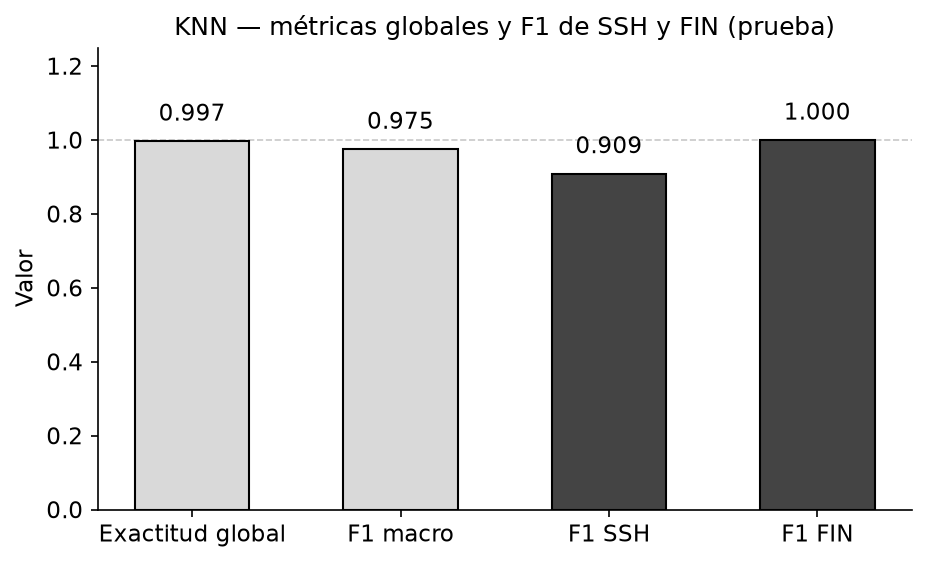

Guardada: resultados/knn/fig1_metricas_globales.png


In [37]:
fig, ax = plt.subplots(figsize=(7.0, 4.0))
nombres_m = ['Exactitud global', 'F1 macro', 'F1 SSH', 'F1 FIN']
vals = [acc, f1_macro, f1_ssh, f1_fin]
x = np.arange(len(nombres_m))
ax.bar(x, vals, width=0.55, color=[LIGHT, LIGHT, GRAY, GRAY], edgecolor=BLACK, linewidth=1.0)
ax.set_ylim(0, 1.25)
ax.set_ylabel('Valor')
ax.set_xticks(x)
ax.set_xticklabels(nombres_m)
ax.set_title('KNN — métricas globales y F1 de SSH y FIN (prueba)')
ax.axhline(1.0, color='#c8c8c8', linewidth=0.8, linestyle='--', zorder=0)
for i, v in enumerate(vals):
    ax.text(i, min(v + 0.04, 1.18), f'{v:.3f}', ha='center', va='bottom', fontsize=11)

ruta1 = DIR_FIGS / 'fig1_metricas_globales.png'
fig.savefig(ruta1, bbox_inches='tight', pad_inches=0.3)
plt.show()
print('Guardada:', ruta1)


### Figura 2. Matriz y métricas de SSH y FIN


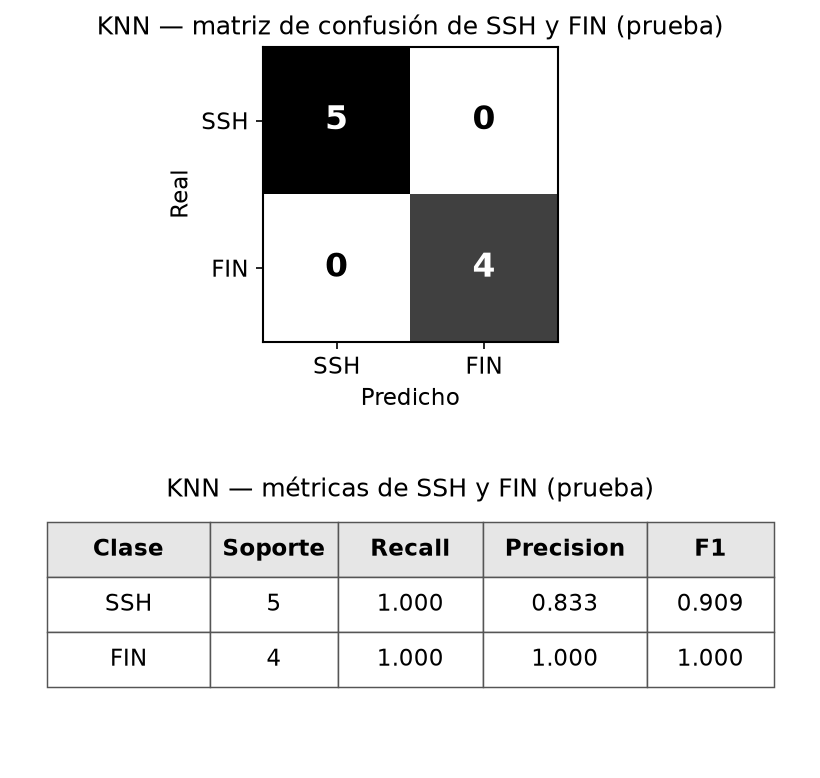

Guardada: resultados/knn/fig2_matriz_y_metricas_ssh_fin.png


In [38]:
fig = plt.figure(figsize=(6.8, 6.2))
gs = gridspec.GridSpec(2, 1, height_ratios=[1.2, 1.0], hspace=0.65)

ax = fig.add_subplot(gs[0])
ax.imshow(cm_ssh_fin, cmap='Greys', vmin=0, vmax=max(5, int(cm_ssh_fin.max())), aspect='equal')
ax.set_xticks([0, 1], ['SSH', 'FIN'])
ax.set_yticks([0, 1], ['SSH', 'FIN'])
ax.set_xlabel('Predicho')
ax.set_ylabel('Real')
ax.set_title('KNN — matriz de confusión de SSH y FIN (prueba)')
for i in range(2):
    for j in range(2):
        v = int(cm_ssh_fin[i, j])
        ax.text(j, i, str(v), ha='center', va='center', fontsize=16,
                color='white' if v >= 3 else BLACK, fontweight='bold')
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color(BLACK)
    spine.set_linewidth(1.0)

ax2 = fig.add_subplot(gs[1])
ax2.axis('off')
ax2.set_title('KNN — métricas de SSH y FIN (prueba)', pad=10)
cols = ['Clase', 'Soporte', 'Recall', 'Precision', 'F1']
rows = [
    ['SSH', str(n_ssh), f'{rec_ssh:.3f}', f'{pre_ssh:.3f}', f'{f1_ssh:.3f}'],
    ['FIN', str(n_fin), f'{rec_fin:.3f}', f'{pre_fin:.3f}', f'{f1_fin:.3f}'],
]
table = ax2.table(cellText=rows, colLabels=cols, loc='upper center', cellLoc='center',
                  colWidths=[0.18, 0.14, 0.16, 0.18, 0.14])
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1.15, 2.2)
for (r, c), cell in table.get_celld().items():
    cell.set_edgecolor('#555555')
    cell.set_linewidth(0.7)
    if r == 0:
        cell.set_facecolor('#e6e6e6')
        cell.get_text().set_fontweight('bold')
    else:
        cell.set_facecolor('white')

ruta2 = DIR_FIGS / 'fig2_matriz_y_metricas_ssh_fin.png'
fig.savefig(ruta2, bbox_inches='tight', pad_inches=0.35)
plt.show()
print('Guardada:', ruta2)
